<a href="https://colab.research.google.com/github/yash-02/Customer-segmentation-Project/blob/main/customer_segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn scipy joblib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path
from scipy.stats import ttest_ind, chi2_contingency

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score,
    confusion_matrix, classification_report
)

from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

sns.set(style="whitegrid")

Load dataset (bundled CSV)

We read the CSV file included in this project directory instead of downloading from
Kaggle, so the notebook runs standalone without external accounts or network access.

In [3]:
BASE_DIR = Path.cwd()
csv_path = BASE_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"
if not csv_path.exists():
    # fallback if the notebook is opened from a different working directory
    csv_path = Path("WA_Fn-UseC_-Telco-Customer-Churn.csv")

df = pd.read_csv(csv_path)
print("DataFrame loaded successfully.")
print(df.head())

DataFrame loaded successfully.
   customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV Strea

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
target_col = "Churn"
print("Shape:", df.shape)
print("\nColumns:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)

Shape: (7043, 21)

Columns:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
 customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object


In [6]:
print("\nMissing values:\n", df.isnull().sum().sort_values(ascending=False).head(20))
print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
dtype: int64

Duplicate rows: 0


In [7]:
df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [8]:
df[target_col]

0        No
1        No
2       Yes
3        No
4       Yes
       ... 
7038     No
7039     No
7040     No
7041    Yes
7042     No
Name: Churn, Length: 7043, dtype: str

# Clean the target column
ML models need the churn target in 0/1 format.




In [9]:
df[target_col] = df[target_col].astype(str).str.strip().str.lower().map({
    "yes": 1, "no": 0,
    "true": 1, "false": 0,
    "1": 1, "0": 0
}).astype(int)

print(df[target_col].value_counts())
print("Churn rate:", df[target_col].mean())

Churn
0    5174
1    1869
Name: count, dtype: int64
Churn rate: 0.2653698707936959


##Convert numeric-looking text columns

Why: Real datasets often store numbers as text, which breaks analysis.

below code is acting like an automated cleaner for your dataset. It hunts for columns that are disguised as text but are actually meant to be numbers, and fixes them so your data analysis tools can actually use them.

Here is a breakdown of exactly how this works, step by step.

The Real-World Analogy
Imagine you have a spreadsheet column for "Monthly Bill." Most entries say 50.00 or 75.50, but a few entries have typos, like a stray space (50.00) or a note ("Free trial"). Because of those few weird entries, Python throws its hands up and labels the entire column as text.

If you try to calculate the average "Monthly Bill," Python will crash because it doesn't know how to do math on text. This code automatically finds those disguised columns, forces the valid numbers into a math-friendly format, and turns the weird text (like "Free trial") into blanks

## Feature engineering: service_count

Why: Counts how many optional services each customer subscribes to. Used later both as
a churn-model feature and as a segmentation feature (mirrors `train.py`).

In [10]:
service_cols = [
    "PhoneService", "OnlineSecurity", "OnlineBackup",
    "TechSupport", "StreamingTV", "StreamingMovies"
]
df["service_count"] = df[service_cols].eq("Yes").sum(axis=1)
df["service_count"].describe()

count    7043.000000
mean        2.597189
std         1.558307
min         0.000000
25%         1.000000
50%         2.000000
75%         4.000000
max         6.000000
Name: service_count, dtype: float64

In [11]:
for col in df.columns:
    if not pd.api.types.is_numeric_dtype(df[col]) and col != target_col:
        converted = pd.to_numeric(df[col], errors="coerce")
        if converted.notna().sum() > 0:
            if converted.notna().sum() / len(df) > 0.7:
                df[col] = converted

df.dtypes

customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
service_count         int64
dtype: object

7) Descriptive analysis

Why: This tells us the average, spread, and distribution of the data.

In [12]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


For numeric columns:

In [13]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.000,0.0000,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.000,55.0000,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.350,89.8500,118.75
TotalCharges,7032.0,2283.300441,2266.771362,18.80,401.45,1397.475,3794.7375,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.000,1.0000,1.00
service_count,7043.0,2.597189,1.558307,0.00,1.00,2.000,4.0000,6.00


For categorical columns:

In [14]:
cat_cols = df.select_dtypes(include="object").columns.tolist()
for col in cat_cols[:10]:
    print("\nColumn:", col)
    print(df[col].value_counts(dropna=False).head(10))


Column: customerID
customerID
7590-VHVEG    1
5575-GNVDE    1
3668-QPYBK    1
7795-CFOCW    1
9237-HQITU    1
9305-CDSKC    1
1452-KIOVK    1
6713-OKOMC    1
7892-POOKP    1
6388-TABGU    1
Name: count, dtype: int64

Column: gender
gender
Male      3555
Female    3488
Name: count, dtype: int64

Column: Partner
Partner
No     3641
Yes    3402
Name: count, dtype: int64

Column: Dependents
Dependents
No     4933
Yes    2110
Name: count, dtype: int64

Column: PhoneService
PhoneService
Yes    6361
No      682
Name: count, dtype: int64

Column: MultipleLines
MultipleLines
No                  3390
Yes                 2971
No phone service     682
Name: count, dtype: int64

Column: InternetService
InternetService
Fiber optic    3096
DSL            2421
No             1526
Name: count, dtype: int64

Column: OnlineSecurity
OnlineSecurity
No                     3498
Yes                    2019
No internet service    1526
Name: count, dtype: int64

Column: OnlineBackup
OnlineBackup
No            

C:\Users\acer\AppData\Local\Temp\ipykernel_25872\3844472138.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include="object").columns.tolist()


8) Visualize the target distribution

Why: We must see whether churn is imbalanced.

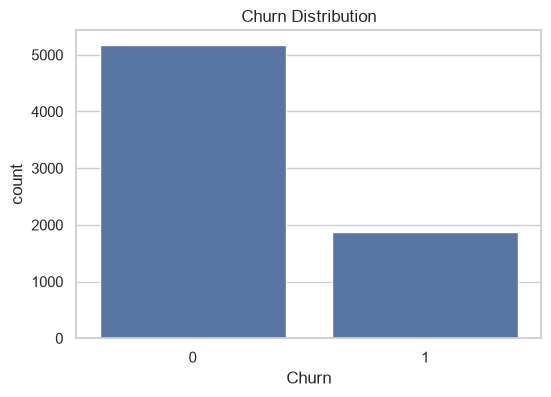

In [15]:
plt.figure(figsize=(6,4))
sns.countplot(x=target_col, data=df)
plt.title("Churn Distribution")
plt.show()

9) Numeric distributions

Why: This helps us understand skewness, spread, and outliers.

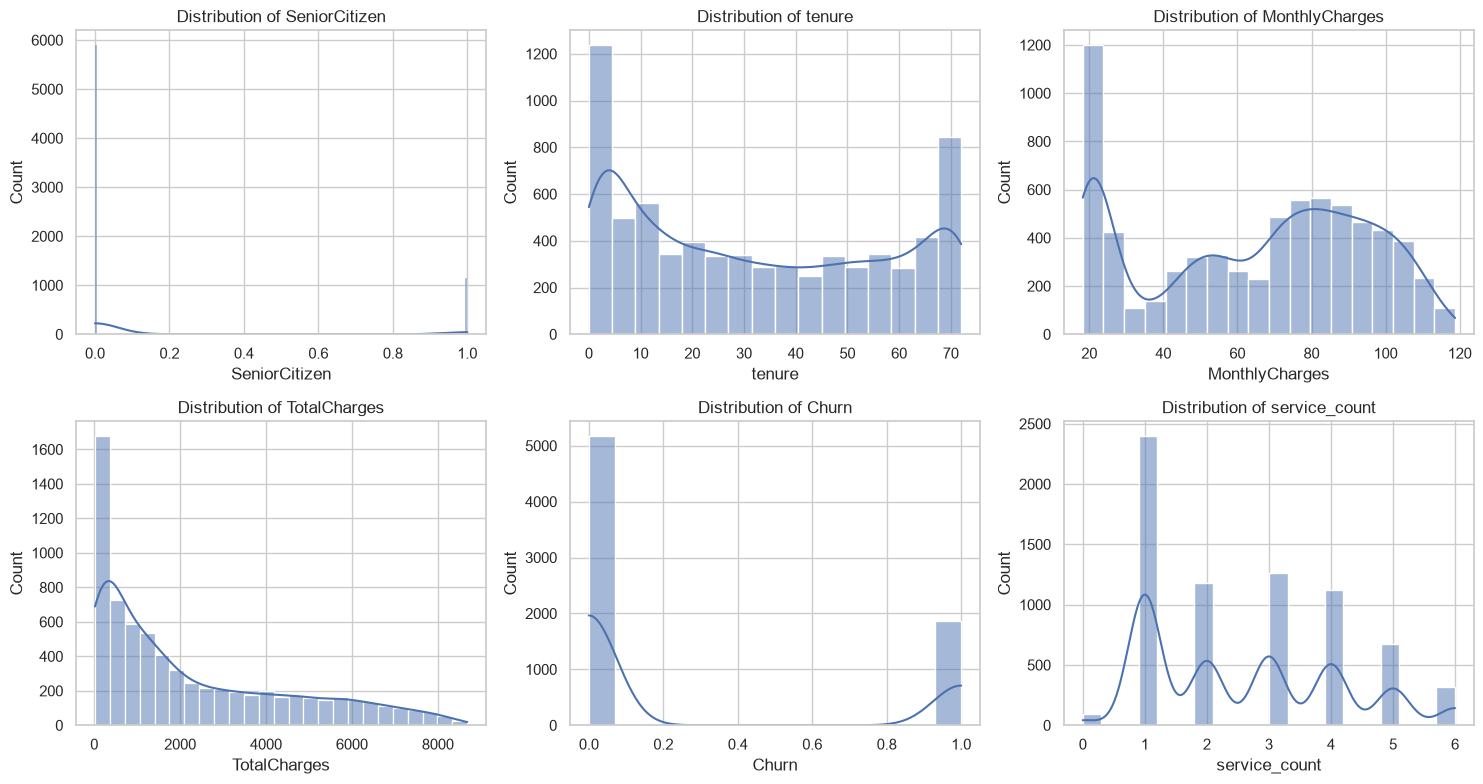

In [16]:
n_cols = 3
n_rows = (len(num_cols) + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4 * n_rows))
axes = axes.flatten()
for i, col in enumerate(num_cols):
    sns.histplot(df[col], kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

pd.crosstab(): This function is used to compute a frequency table of two or more factors.
df['SeniorCitizen']: This is the first variable used for grouping, indicating whether a customer is a senior citizen.
df['Churn']: This is the second variable, representing whether a customer churned.
normalize='index': This argument normalizes the values across each row (index)

In [17]:
pd.crosstab(
    df['SeniorCitizen'],
    df['Churn'],
    normalize='index'
)

Churn,0,1
SeniorCitizen,,
0,0.763938,0.236062
1,0.583187,0.416813


in analysis

When we ask:

"Do senior citizens churn more?"

we mean:

"Are senior citizens more likely to leave the company than non-senior citizens?"

For example:

SeniorCitizen	Churn Rate

Interpretation:

Non-Senior Customers:
24% leave

Senior Customers:
42% leave

This would tell us:

Senior citizens are much more likely to churn.

and the business may create special retention programs for them.

10) Boxplots by churn

Why: We want to see whether churned and non-churned customers differ.

<Axes: xlabel='Churn', ylabel='tenure'>

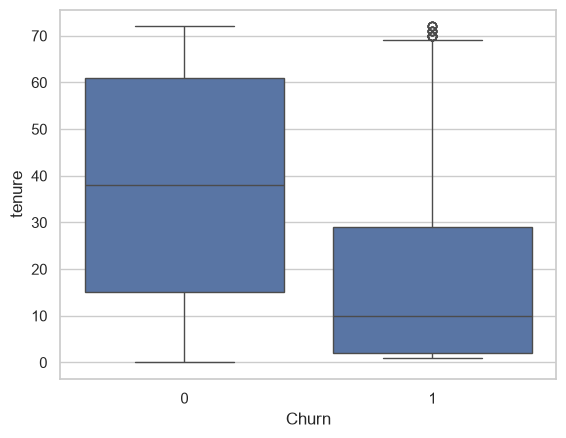

In [18]:
sns.boxplot(
    x='Churn',
    y='tenure',
    data=df
)

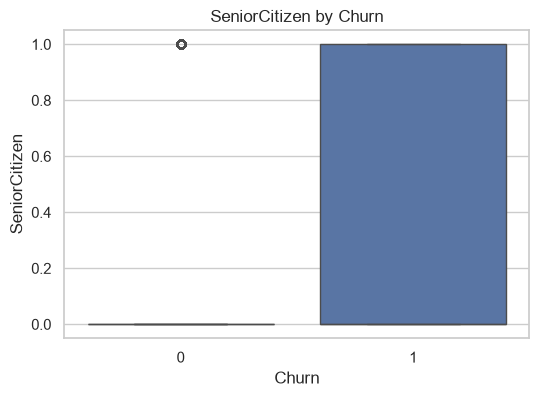

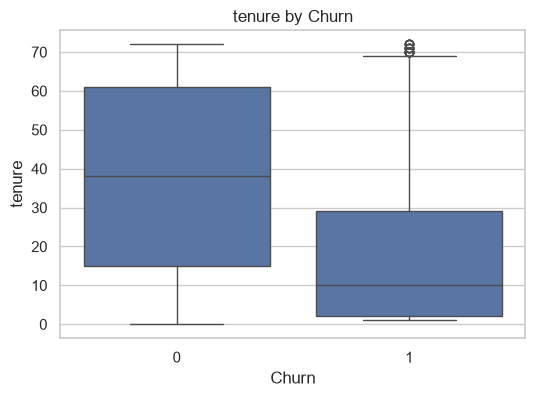

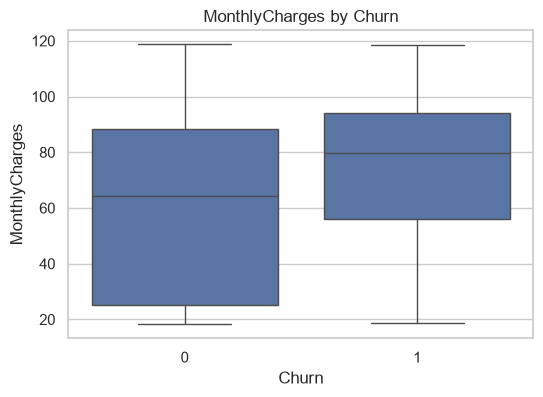

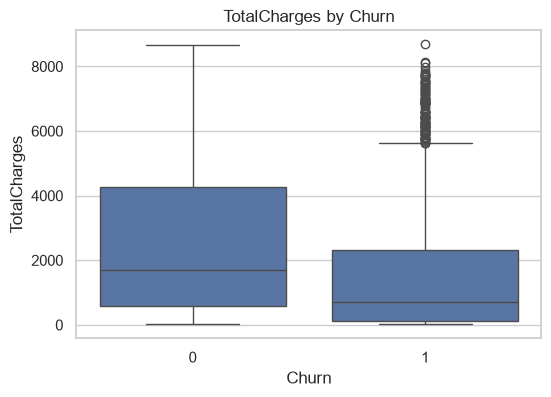

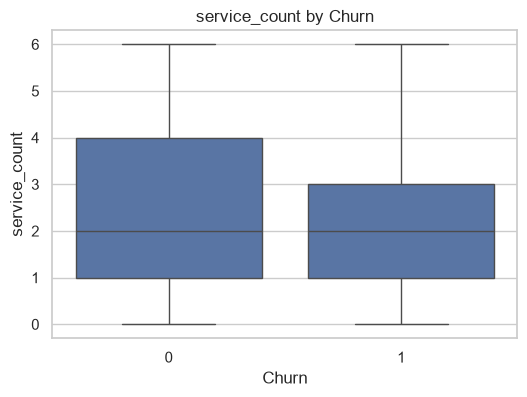

In [19]:
for col in num_cols[:6]:
    if col != target_col:
        plt.figure(figsize=(6,4))
        sns.boxplot(x=target_col, y=col, data=df)
        plt.title(f"{col} by Churn")
        plt.show()

11) Categorical features vs churn

Why: This shows whether specific categories are linked to churn.

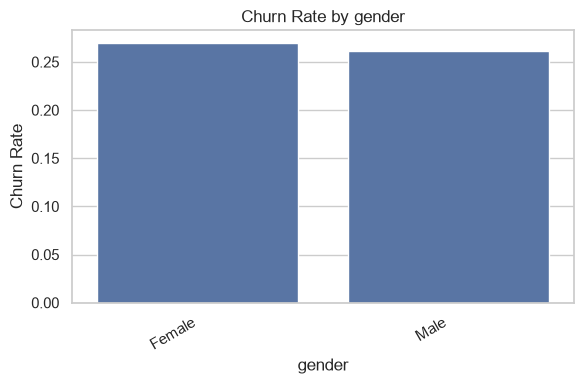

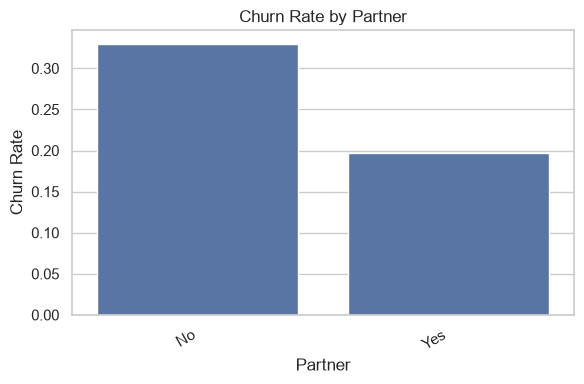

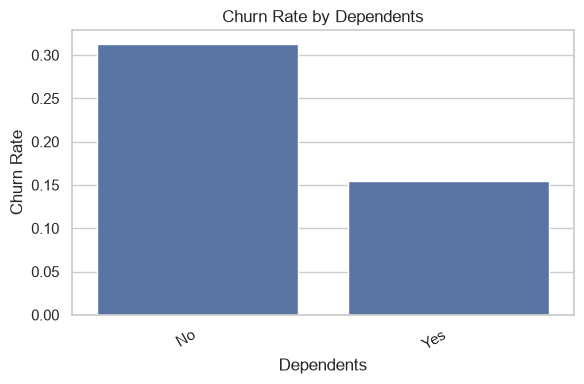

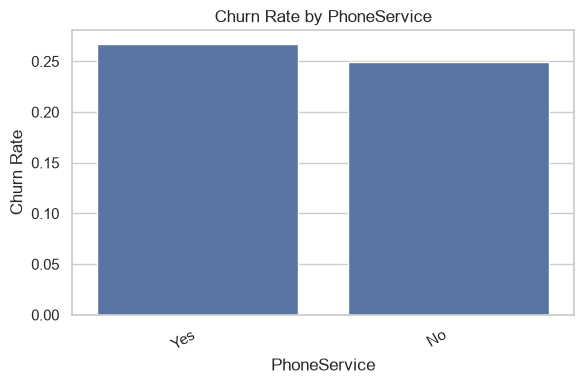

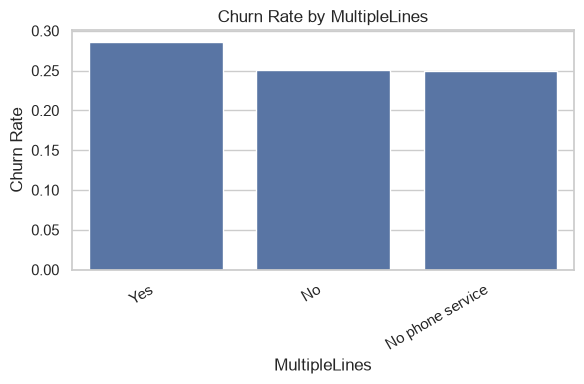

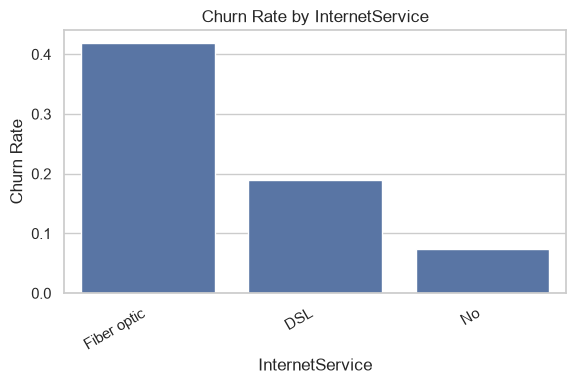

In [20]:
cat_plot_cols = [c for c in cat_cols if c not in (target_col, "customerID")][:6]

for col in cat_plot_cols:
    churn_rate_by_cat = df.groupby(col)[target_col].mean().sort_values(ascending=False)
    plt.figure(figsize=(6,4))
    sns.barplot(x=churn_rate_by_cat.index, y=churn_rate_by_cat.values)
    plt.title(f"Churn Rate by {col}")
    plt.ylabel("Churn Rate")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

12) Correlation heatmap

Why: This helps us detect strong numeric relationships.

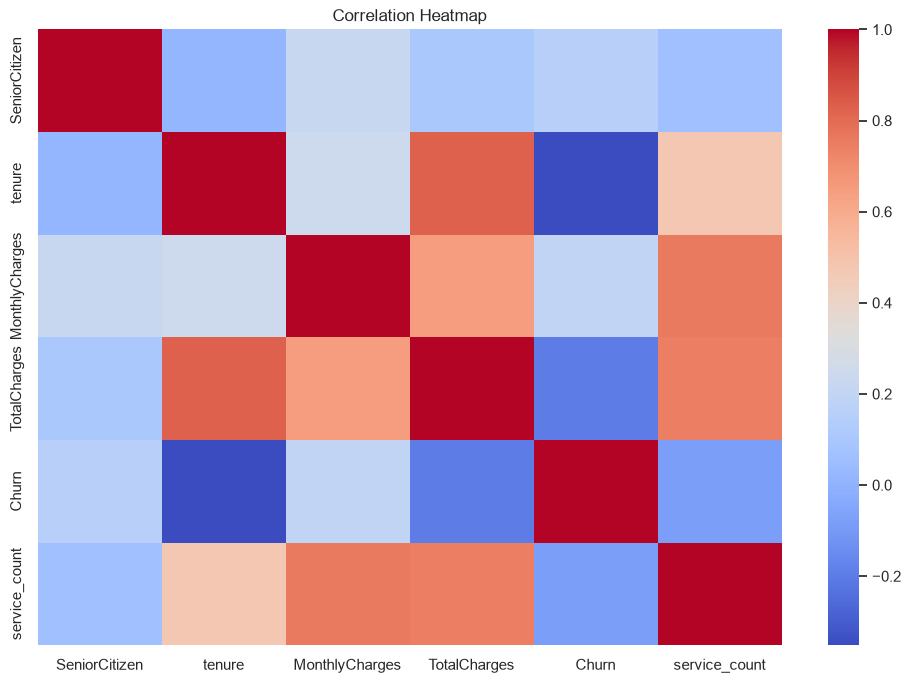

In [21]:
plt.figure(figsize=(12,8))
sns.heatmap(df[num_cols].corr(), annot=False, cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.show()


13) Hypothesis testing

Why: This gives statistical evidence, not just visual guesses.

13A) t-test for numeric columns

Question: Is the mean different between churned and non-churned customers?

In [22]:
t_test_results = []

for col in num_cols:
    if col != target_col:
        g0 = df[df[target_col] == 0][col].dropna()
        g1 = df[df[target_col] == 1][col].dropna()
        if len(g0) > 1 and len(g1) > 1:
            stat, p = ttest_ind(g0, g1, equal_var=False)
            t_test_results.append([col, stat, p])

t_test_df = pd.DataFrame(t_test_results, columns=["feature", "t_stat", "p_value"])
t_test_df = t_test_df.sort_values("p_value")
t_test_df.head(10)

,feature,t_stat,p_value
1,tenure,34.823819,1.195495e-232
3,TotalCharges,18.800768,1.152494e-75
2,MonthlyCharges,-18.407527,8.592449e-73
0,SeniorCitizen,-11.343877,3.587587e-29
4,service_count,7.618749,3.160547e-14


The Rule: A p-value < 0.05 is the standard scientific threshold to declare a result "statistically significant." * All your results here have extremely tiny p-values (the e-232 means the decimal point is moved 232 places to the left). This means these features are definitely related to whether a customer churns.

t-stat (T-statistic): This indicates the direction and strength of the difference.

A positive number means the average for "stayed" customers is higher.

A negative number means the average for "stayed" customers is lower.

What the Results Tell Us
Based on this table, you have found strong evidence that these four features are powerful predictors of customer churn:

Tenure: Highly significant. There is a very strong relationship between how long a customer stays and whether they churn.

TotalCharges & MonthlyCharges: Both are highly significant, confirming that cost is a major factor in customer decisions.

SeniorCitizen: Also significant, suggesting that age group plays a measurable role in whether someone stays or leaves.

In [23]:
print("Features with p < 0.05 are statistically significant.")
print(t_test_df[t_test_df["p_value"] < 0.05].head(10))

Features with p < 0.05 are statistically significant.
          feature     t_stat        p_value
1          tenure  34.823819  1.195495e-232
3    TotalCharges  18.800768   1.152494e-75
2  MonthlyCharges -18.407527   8.592449e-73
0   SeniorCitizen -11.343877   3.587587e-29
4   service_count   7.618749   3.160547e-14


13B) Chi-square test for categorical columns

Question: Is the category associated with churn?

In [24]:
chi_results = []

for col in cat_cols:
    if col != target_col:
        table = pd.crosstab(df[col].fillna("Missing"), df[target_col])
        if table.shape[0] > 1 and table.shape[1] == 2:
            stat, p, dof, expected = chi2_contingency(table)
            chi_results.append([col, stat, p])

chi_df = pd.DataFrame(chi_results, columns=["feature", "chi2_stat", "p_value"]).sort_values("p_value")
chi_df.head(10)

,feature,chi2_stat,p_value
13,Contract,1184.596572,5.863038e-258
7,OnlineSecurity,849.998968,2.661150e-185
10,TechSupport,828.197068,1.443084e-180
6,InternetService,732.309590,9.571788e-160
15,PaymentMethod,648.142327,3.682355e-140
8,OnlineBackup,601.812790,2.079759e-131
9,DeviceProtection,558.419369,5.505219e-122
12,StreamingMovies,375.661479,2.667757e-82
11,StreamingTV,374.203943,5.528994e-82
14,PaperlessBilling,258.277649,4.073355e-58


14) Define feature columns

Why: We separate input features from target.

In [25]:
id_cols = ["customerID"]   # customerID is an identifier, not a predictive feature

X = df.drop(columns=[target_col] + id_cols, errors="ignore")
y = df[target_col]

num_features = X.select_dtypes(include=np.number).columns.tolist()
cat_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric:", num_features)
print("Categorical:", cat_features)

Numeric: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'service_count']
Categorical: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


15) Preprocessing pipeline

Why: We need missing-value handling, scaling, and one-hot encoding.

In [26]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, num_features),
    ("cat", categorical_pipeline, cat_features)
])

16) Train-test split

Why: We must evaluate on unseen data.

In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

17) Train churn models

Why: Start with a simple baseline, then try a stronger model.

Logistic Regression

In [28]:
log_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=3000, class_weight="balanced"))
])

log_model.fit(X_train, y_train)
log_pred = log_model.predict(X_test)
log_proba = log_model.predict_proba(X_test)[:, 1]

Random Forest

In [29]:
rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced_subsample",
        min_samples_leaf=2
    ))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

18) Evaluate models

Why: Accuracy alone is not enough. We need recall, precision, F1, ROC-AUC, and PR-AUC.

In [30]:
def evaluate_model(y_true, pred, proba, name):
    print(f"\n{name}")
    print("Accuracy:", accuracy_score(y_true, pred))
    print("Precision:", precision_score(y_true, pred))
    print("Recall:", recall_score(y_true, pred))
    print("F1:", f1_score(y_true, pred))
    print("ROC-AUC:", roc_auc_score(y_true, proba))
    print("PR-AUC:", average_precision_score(y_true, proba))
    print("\nClassification Report:\n", classification_report(y_true, pred))

evaluate_model(y_test, log_pred, log_proba, "Logistic Regression")
evaluate_model(y_test, rf_pred, rf_proba, "Random Forest")


Logistic Regression
Accuracy: 0.7381121362668559
Precision: 0.504302925989673
Recall: 0.7834224598930482
F1: 0.6136125654450262
ROC-AUC: 0.8414890593918726
PR-AUC: 0.6325205335510823

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409


Random Forest
Accuracy: 0.7764371894960965
Precision: 0.5710843373493976
Recall: 0.6336898395721925
F1: 0.6007604562737643
ROC-AUC: 0.831943475677491
PR-AUC: 0.6338420590522017

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.83      0.84      1035
           1       0.57      0.63      0.60       374

    accuracy                           0.78      1409
   macro avg       0.72      0.73      0.72

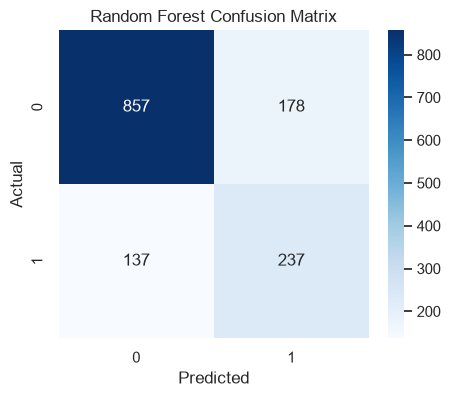

In [31]:
plt.figure(figsize=(5,4))
sns.heatmap(confusion_matrix(y_test, rf_pred), annot=True, fmt="d", cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

20) About model persistence in this notebook

The Random Forest above is a prototype used for exploration only. The productionized
churn model (5 candidates compared with 5-fold cross-validation, an imbalance-aware
ROC-AUC selection metric, leakage-free out-of-fold threshold tuning, light
hyperparameter search, and SHAP explainability) lives in `train.py`, which is the sole
script that writes to `models/`. This notebook does not persist model files, to avoid
having two different, inconsistent sets of "the churn model" floating around the repo.

In [32]:
print("Prototype Random Forest kept in-memory only (not saved to disk).")
print("See train.py for the productionized model that is saved to models/churn_model.joblib.")

Prototype Random Forest kept in-memory only (not saved to disk).
See train.py for the productionized model that is saved to models/churn_model.joblib.


21) Make churn predictions for all customers

Why: This creates business-ready output.

In [33]:
df["churn_probability"] = rf_model.predict_proba(X)[:, 1]
df["predicted_churn"] = (df["churn_probability"] >= 0.5).astype(int)

df[["churn_probability", "predicted_churn"]]

,churn_probability,predicted_churn
0,0.490281,0
1,0.033808,0
2,0.743227,1
3,0.029234,0
4,0.801042,1
...,...,...
7038,0.110953,0
7039,0.189027,0
7040,0.180949,0
7041,0.864406,1


Top risky customers:

In [34]:
df.sort_values("churn_probability", ascending=False).head(20)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,service_count,churn_probability,predicted_churn
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,99.65,820.50,1,3,0.988149,1
2577,4910-GMJOT,Female,0,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,94.60,94.60,1,3,0.986107,1
3209,8149-RSOUN,Female,0,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,93.85,93.85,1,3,0.985839,1
2891,0495-RVCBF,Female,0,No,No,1,Yes,No,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,79.70,79.70,1,2,0.984191,1
1026,4822-RVYBB,Male,1,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,100.60,819.40,1,3,0.982979,1
1976,9497-QCMMS,Male,1,No,No,1,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,93.55,93.55,1,3,0.980851,1
6232,9681-OXGVC,Female,0,No,No,5,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,100.50,514.00,1,3,0.980643,1
1148,7851-WZEKY,Female,0,No,No,2,Yes,Yes,Fiber optic,No,...,Yes,Month-to-month,Yes,Electronic check,95.15,196.90,1,3,0.979810,1
6491,9728-FTTVZ,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,69.20,69.20,1,1,0.979493,1
6764,7660-HDPJV,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,69.20,69.20,1,1,0.979493,1


22) Customer segmentation

Why: Churn tells us who may leave. Segmentation tells us which customer groups exist.

We will cluster customers using the same feature set.

In [35]:
segment_cols = ["tenure", "MonthlyCharges", "TotalCharges", "service_count"]
seg_X = df[segment_cols].copy()
seg_X.describe()

,tenure,MonthlyCharges,TotalCharges,service_count
count,7043.000000,7043.000000,7032.000000,7043.000000
mean,32.371149,64.761692,2283.300441,2.597189
std,24.559481,30.090047,2266.771362,1.558307
min,0.000000,18.250000,18.800000,0.000000
25%,9.000000,35.500000,401.450000,1.000000
50%,29.000000,70.350000,1397.475000,2.000000
75%,55.000000,89.850000,3794.737500,4.000000
max,72.000000,118.750000,8684.800000,6.000000


Preprocess for clustering:

We scale the numeric segmentation features (tenure, MonthlyCharges, TotalCharges,
service_count) with StandardScaler. No categorical/ID columns go into this -- an
earlier version of this notebook accidentally one-hot encoded `customerID` into the
clustering features, which silently destroyed the cluster structure (every customer
got a near-unique dummy column, and the silhouette scan below picked a degenerate
k=2 as a result). Keeping segmentation restricted to numeric, business-meaningful
features avoids that, and mirrors `train.py`.

In [36]:
seg_scaler = StandardScaler()
seg_transformed = seg_scaler.fit_transform(seg_X.fillna(seg_X.median()))

23) Find the best number of clusters

Why: We need a reasonable number of customer groups.

In [37]:
scores = []

for k in range(2, 9):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(seg_transformed)
    score = silhouette_score(seg_transformed, labels)
    scores.append((k, score))

score_df = pd.DataFrame(scores, columns=["k", "silhouette_score"])
score_df

,k,silhouette_score
0,2,0.459019
1,3,0.405715
2,4,0.401993
3,5,0.381324
4,6,0.375411
5,7,0.364253
6,8,0.377894


Plot:

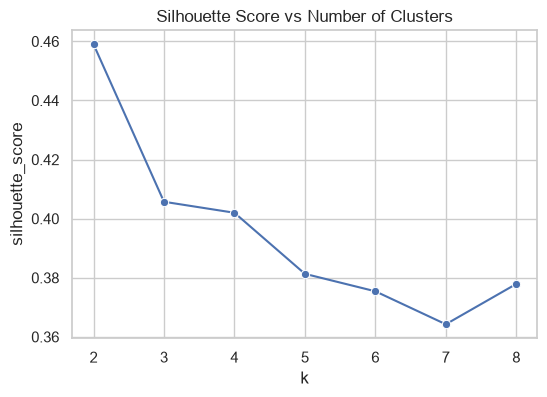

In [38]:
plt.figure(figsize=(6,4))
sns.lineplot(data=score_df, x="k", y="silhouette_score", marker="o")
plt.title("Silhouette Score vs Number of Clusters")
plt.show()

Choose best k:

The silhouette score alone is often maximized at a small, business-unhelpful k (here
k=2, essentially "everyone vs everyone else"). For actionable segmentation we restrict
the search to a business-usable range (k=3 to 6) and pick the best silhouette score
within that range -- the same rule `train.py` uses.

In [39]:
business_k_range = score_df[score_df["k"].between(3, 6)]
best_row = business_k_range.sort_values("silhouette_score", ascending=False).iloc[0]
best_k = int(best_row["k"])
print("Best k in business-usable range (3-6):", best_k)

Best k in business-usable range (3-6): 3


24) Fit KMeans

Why: This assigns each customer to a segment.

In [40]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["cluster"] = kmeans.fit_predict(seg_transformed)

df["cluster"].value_counts().sort_index()

cluster
0    2181
1    2617
2    2245
Name: count, dtype: int64

25) Visualize clusters in 2D

Why: This gives a simple picture of the segments.

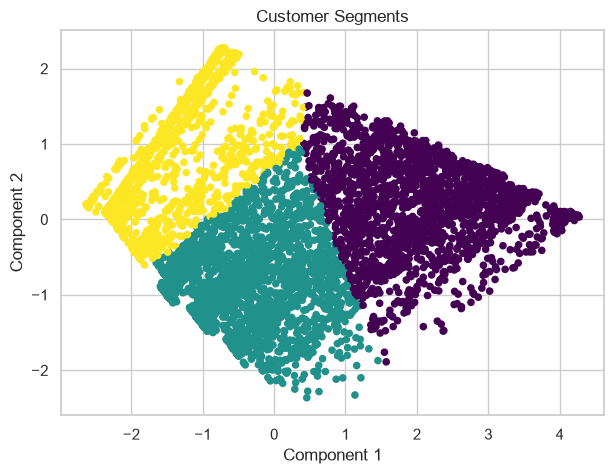

In [41]:
svd = TruncatedSVD(n_components=2, random_state=42)
coords = svd.fit_transform(seg_transformed)

plt.figure(figsize=(7,5))
plt.scatter(coords[:, 0], coords[:, 1], c=df["cluster"], cmap="viridis", s=20)
plt.title("Customer Segments")
plt.xlabel("Component 1")
plt.ylabel("Component 2")
plt.show()

26) Profile each segment

Why: We need to understand what each cluster means.

In [42]:
cluster_profile = (
    df.groupby("cluster")
    .agg(
        size=("cluster", "size"),
        avg_tenure=("tenure", "mean"),
        avg_monthly_charges=("MonthlyCharges", "mean"),
        avg_total_charges=("TotalCharges", "mean"),
        avg_service_count=("service_count", "mean"),
        churn_rate=(target_col, "mean"),
    )
    .reset_index()
    .sort_values("churn_rate", ascending=False)
)
cluster_profile

,cluster,size,avg_tenure,avg_monthly_charges,avg_total_charges,avg_service_count,churn_rate
1,1,2617,15.187237,75.785881,1148.300861,2.544517,0.457776
2,2,2245,27.219154,27.150690,719.313377,1.071269,0.154566
0,0,2181,58.293443,90.248349,5248.172490,4.231087,0.148556


In [43]:
print("Segment profile above mirrors the data-driven segmentation approach in train.py.")
print("train.py re-fits this same approach on the full pipeline and persists the")
print("production artifacts (models/kmeans.joblib, models/preprocessor.joblib,")
print("models/segment_names.joblib) used by app.py -- this notebook stays exploratory")
print("and doesn't write model files itself.")

Segment profile above mirrors the data-driven segmentation approach in train.py.
train.py re-fits this same approach on the full pipeline and persists the
production artifacts (models/kmeans.joblib, models/preprocessor.joblib,
models/segment_names.joblib) used by app.py -- this notebook stays exploratory
and doesn't write model files itself.


## Summary & handoff to the production pipeline

This notebook covers EDA, hypothesis testing (t-test, chi-square), prototype churn
models (Logistic Regression, Random Forest), and a data-driven customer segmentation.
The productionized version of this pipeline lives in `train.py`, which extends the
churn modeling here with 5-fold cross-validation, an imbalance-aware ROC-AUC
selection metric, leakage-free threshold tuning on out-of-fold predictions, light
hyperparameter search, and SHAP explainability -- and uses the same silhouette-selected
segmentation approach. `train.py` is the sole script that writes to `models/`, which
`app.py` loads for the live dashboard.